<a href="https://colab.research.google.com/github/edsonportosilva/OpticalCommunications/blob/main/jupyter%20notebooks/English/3.%20Optical%20fiber.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
if 'google.colab' in str(get_ipython()):    
    ! git clone -b main https://github.com/edsonportosilva/OptiCommPy
    from os import chdir as cd
    cd('/content/OptiCommPy/')
    ! pip install .
    cd('/content/')
    ! wget https://raw.githubusercontent.com/edsonportosilva/OpticalCommunications/main/jupyter%20notebooks/English/utils.py

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Sellmeier-Equation" data-toc-modified-id="Sellmeier-Equation-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Sellmeier Equation</a></span></li><li><span><a href="#Bessel-Functions" data-toc-modified-id="Bessel-Functions-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Bessel Functions</a></span><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#First-species-Bessel-Function---$J_m(x)$" data-toc-modified-id="First-species-Bessel-Function---$J_m(x)$-2.0.1"><span class="toc-item-num">2.0.1&nbsp;&nbsp;</span>First-species Bessel Function species - $J_m(x)$</a></span></li><li><span><a href="#Bessel-Function-of-second-species---$Y_m(x)$" data-toc-modified-id="Bessel-Function-of-second-species---$Y_m(x)$-2.0.2"><span class="toc-item-num">2.0.2&nbsp;&nbsp;</span>Bessel function of the second kind - $Y_m(x)$</a></span></li><li><span><a href="#Modified-Bessel-function-of-the-first-kind---$I_m(x)$" data-toc-modified-id="First-species-modified-Bessel-function---$I_m(x)$-2.0.3"><span class="toc-item-num">2.0.3&nbsp;&nbsp;</span>First-species modified Bessel function - $I_m(x)$</a></span></li><li><span><a href="#Modified-Bessel-Function-of-the-second-species---$K_m(x)$" data-toc-modified-id="Modified-Bessel-Function-of-the-second-species---$K_m(x)$-2.0.4"><span class="toc-item-num">2.0.4&nbsp;&nbsp;</span>Modified Bessel function of the second kind - $K_m(x)$</a></span></li></ul></li></ul></li><li><span><a href="#Equation-characteristic" data-toc-modified-id="Equation-characteristic-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Characteristic equation</a></span><ul class="toc-item"><li><span><a href="#Solution-of-characteristic-equation" data-toc-modified-id="Solution-of-characteristic-equation-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Solution of the characteristic equation</a></span><ul class="toc-item"><li><span><a href="#Field-Intensity" data-toc-modified-id="Field-Intensity-3.1.1"><span class="toc-item-num">3.1.1&nbsp;&nbsp;</span>Field strength</a></span></li></ul></li><li><span><a href="#Spot-size" data-toc-modified-id="Spot-size-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Spot size</a></span></li></ul></li></ul></div>

In [2]:
from optic.utils import parameters
from IPython.core.display import HTML
from IPython.core.pylabtools import figsize
from IPython.display import display, Math

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

In [3]:
import numpy as np
import scipy.special as sp
from  scipy.constants import c
import matplotlib.pyplot as plt
from optic.dsp.core import firFilter, pulseShape, lowPassFIR
from optic.plot import eyediagram
from commpy.utilities  import upsample #chưa chắc nằm thư viên này được không
from optic.comm.metrics import signalPower
from optic.models.devices import mzm

In [4]:
SMALL_SIZE = 14
MEDIUM_SIZE = 14
BIGGER_SIZE = 14

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# Sellmeier equation

The Sellmeier equation describes the refractive index of a material as a function of angular frequency:
\begin{equation}
n^2\left( \omega \right) = 1 + \sum_{j = 1}^m
\frac{B_j \omega_j^2}{\omega_j^2 - \omega^2},
\end{equation}
where $\omega_j$ is the resonance frequency and $B_j$ the coefficient of the $j$-th resonance frequency. For silica, these parameters are:

In [5]:
Bj = np.array([0.6961663, 0.4079426, 0.8974794])
#Tạo mảng NumPy Bj chứa 3 hệ số cường độ dao động cộng hưởng thực nghiệm B1, B2, B3 của thủy tinh Silica.
lmbdj = np.array([0.0684043e-6, 0.1162414e-6, 9.8961610e-6])
# Tạo mảng NumPy lmbdj chứa 3 bước sóng cộng hưởng thực nghiệm λ1, λ2, λ3 của thủy tinh Silica. dvi um (đã tính luôn 10^-6)

where $\lambda_j = 2\pi c \backslash \omega_j$.

In [6]:
lmbd_max = 1.6e-6 # Tạo biến lmbd_max chứa giá trị bước sóng tối đa 1.6e-6 m (1.6 μm) để sử dụng trong việc tính toán chiết suất của thủy tinh Silica.
lmbd_min = 1.5e-6 # Khai báo giới hạn bước sóng cực tiểu
lmbd = np.linspace(lmbd_min, lmbd_max, 1000) #Tạo mảng lmbd gồm 1000 điểm bước sóng chia đều từ 1500nm đến 1600nm.
n = 1 # Khởi tạo biến n (là giá trị n^2) bằng 1 để tính toán chiết suất của thủy tinh Silica, tương ứng số hạng hằng số 1 trong công thức Sellmeier
for i in range(3):
  n = n + (Bj[i]*lmbd**2)/(lmbd**2 - lmbdj[i]**2)
#Vòng lặp for chạy i từ 0 đến 2 để tính tổng các hệ số Sellmeier cho thủy tinh Silica. Trong mỗi vòng lặp, giá trị của n được cập nhật bằng cách cộng thêm một phần tử của công thức Sellmeier, sử dụng hệ số Bj[i] và bước sóng cộng hưởng lmbdj[i]. Kết quả cuối cùng là giá trị chiết suất n^2 của thủy tinh Silica tại các bước sóng trong mảng lmbd.

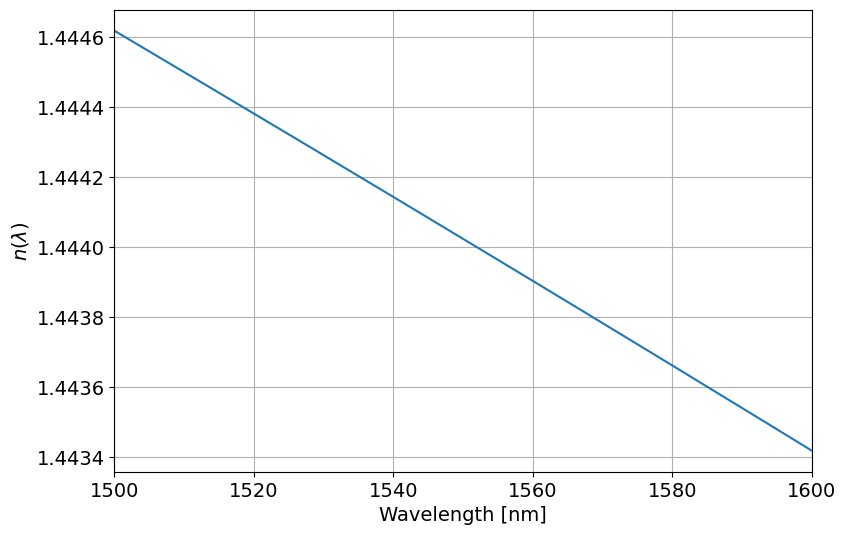

In [7]:
plt.figure(figsize=(9,6)) #khung hình 9x6
plt.plot(1e9*lmbd, np.sqrt(n)) # Vẽ đồ thị chiết suất n (là căn bậc hai của n^2) của thủy tinh Silica theo bước sóng λ (được chuyển đổi sang đơn vị nanomet bằng cách nhân với 1e9).
plt.xlabel('Wavelength [nm]')
plt.ylabel(r'$n\left( \lambda \right)$')
plt.xlim([1e9*lmbd_min, 1e9*lmbd_max])
plt.grid(True)

# Bessel Functions

### Bessel function of the first kind - $J_m(x)$

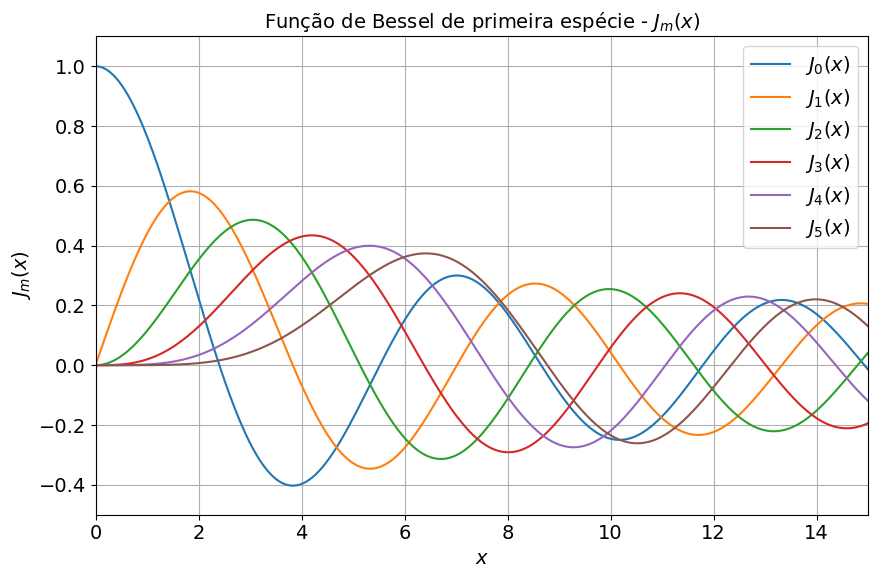

In [8]:
plt.figure(figsize=(9,6))
x = np.linspace(0, 15, 500) 
  #Tạo mảng x gồm 500 điểm dữ liệu trải đều trong khoảng từ 0 đến 15. Biến x đại diện cho trục khoảng cách bán kính chuẩn hóa r/a.

for v in range(0, 6): #Sử dụng vòng lặp for chạy bậc v từ 0 đến 5 (tương ứng với m = 0, 1, 2, 3, 4, 5)
  plt.plot(x, sp.jv(v, x))
  # Gọi hàm jv(v, x) từ module scipy.special để tính giá trị hàm Bessel loại 1 bậc v (tương đương m) tại các điểm x
  
plt.xlim((0, 15))
plt.ylim((-0.5, 1.1))
plt.legend((r'${J}_0(x)$', r'${J}_1(x)$', r'${J}_2(x)$', 
            r'${J}_3(x)$', r'${J}_4(x)$', r'${J}_5(x)$'), loc = 0)
plt.xlabel(r'$x$')
plt.ylabel(r'${J}_m(x)$')
plt.title(r'Função de Bessel de primeira espécie - ${J}_m(x)$')
plt.grid(True)
plt.tight_layout()

### Bessel function of the second kind - $Y_m(x)$

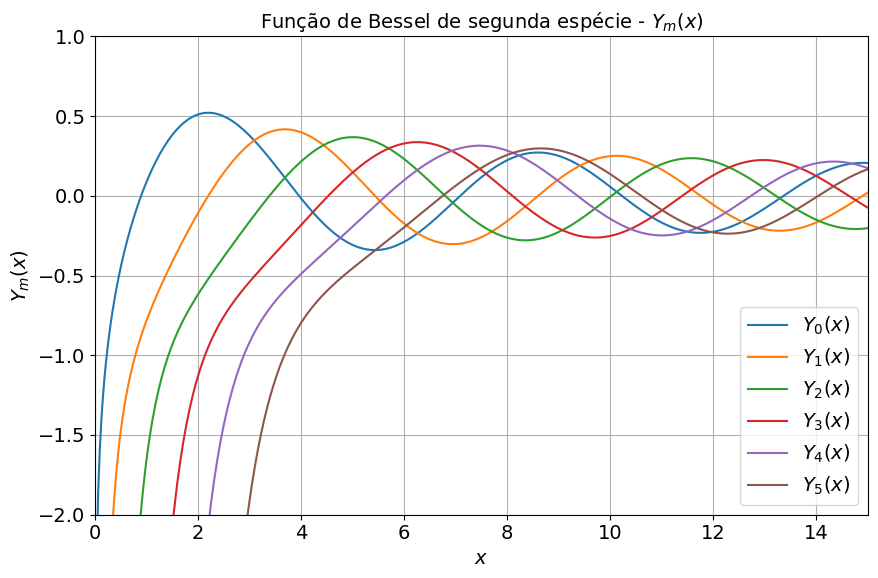

In [9]:
plt.figure(figsize=(9,6))
for v in range(0, 6):
  plt.plot(x, sp.yv(v, x))
  
plt.xlim((0, 15))
plt.ylim((-0.5, 1.1))
plt.legend((r'${Y}_0(x)$', r'${Y}_1(x)$', r'${Y}_2(x)$', 
            r'${Y}_3(x)$', r'${Y}_4(x)$', r'${Y}_5(x)$'), loc = 0)
plt.xlabel(r'$x$')
plt.ylabel(r'${Y}_m(x)$')
plt.title(r'Função de Bessel de segunda espécie - ${Y}_m(x)$')
plt.ylim([-2.0,1.0])
plt.grid(True)
plt.tight_layout()

### Modified Bessel function of the first kind - $I_m(x)$

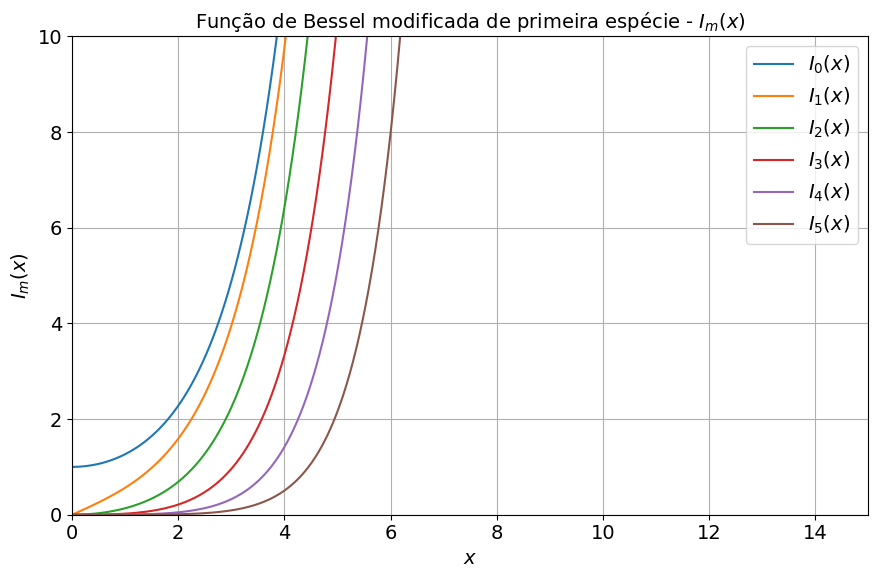

In [10]:
plt.figure(figsize=(9,6))
for v in range(0, 6):
  plt.plot(x, sp.iv(v, x))
  
plt.xlim((0, 15))
plt.ylim((-0.5, 1.1))
plt.legend((r'${I}_0(x)$', r'${I}_1(x)$', r'${I}_2(x)$', 
            r'${I}_3(x)$', r'${I}_4(x)$', r'${I}_5(x)$'), loc = 0)
plt.xlabel(r'$x$')
plt.ylabel(r'${I}_m(x)$')
plt.title(r'Função de Bessel modificada de primeira espécie - ${I}_m(x)$')
plt.ylim([0.0,10.0])
plt.grid(True)
plt.tight_layout()

### Modified Bessel function of the second kind - $K_m(x)$

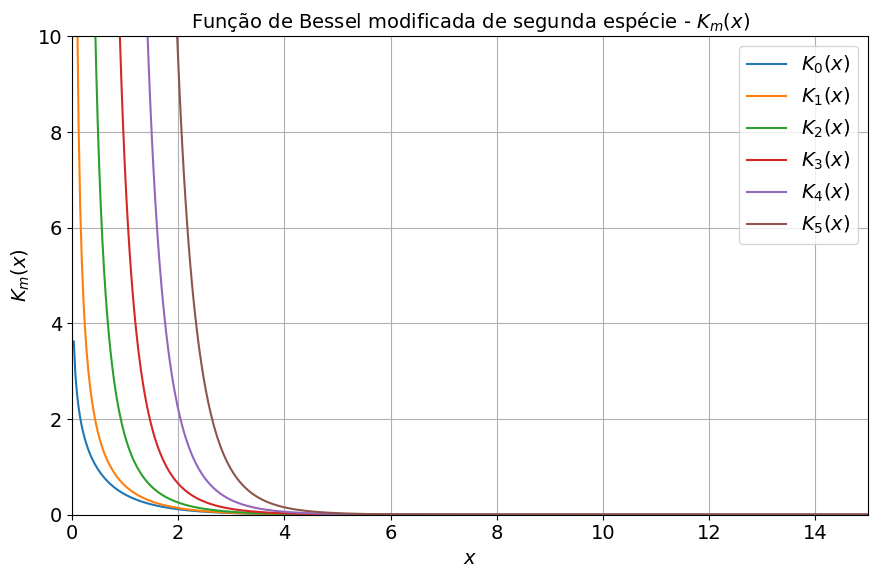

In [11]:
plt.figure(figsize=(9,6))
for v in range(0, 6):
  plt.plot(x, sp.kv(v, x))
  
plt.xlim((0, 15))
plt.ylim((-0.5, 1.1))
plt.legend((r'${K}_0(x)$', r'${K}_1(x)$', r'${K}_2(x)$', 
            r'${K}_3(x)$', r'${K}_4(x)$', r'${K}_5(x)$'), loc = 0)
plt.xlabel(r'$x$')
plt.ylabel(r'${K}_m(x)$')
plt.title(r'Função de Bessel modificada de segunda espécie - ${K}_m(x)$')
plt.ylim([0.0,10.0])
plt.grid(True)
plt.tight_layout()

# Characteristic equation

The characteristic equation of optical fiber is:
\begin{equation}
\left[ \frac{J'_m\left( p a \right)}{pJ_m\left( p a \right)} + \frac{K'_m\left( q a \right)}{q K_m\left( q a \right)} \right]\left[ \frac{J'_m\left( p a \right)}{pJ_m\left( p a \right)} + \frac{n_2^2}{n_1^2} \frac{K'_m\left( q a \right)}{q K_m\left( q a \right)} \right] = \left( \frac{m}{a} \right)^2 \left( \frac{1}{p^2} + \frac{1}{q^2} \right)\left( \frac{1}{p^2} + \frac{n_2^2}{n_1^2} \frac{1}{q^2} \right),
\end{equation}
where $a$ is the radius of the fiber core and $m$ the order of the Bessel function.

In [12]:
a    = 4.5e-6                # fiber core radius: bán kính lõi sợi quang 
n1   = 1.448918              # core index: chiết suất core quang 
n2   = 1.444418              # shell index: chiết suất vỏ sợi quang
NA   = np.sqrt(n1**2-n2**2)  # numerical aperture: tính khẩu độ số gần bằng 0,114
lmbd = 1550e-9               # operating wavelength: Bước sóng ánh sáng hoạt động lambda = 1550nm (băng C chuẩn viễn thông).
k0   = 2*np.pi/lmbd          # wave number in free space: Tính số sóng trong chân không k0 = 2*pi/lambda}.
V    = a*k0*NA               # normalized operating frequency:  Tính tần số chuẩn hóa V
print("(n2/n1)^2 = %4.3f" % ((n2/n1)**2)) #tỉ số n1/n2 tất cả bình phương
print("V = %4.2f" %(V)) # in V

(n2/n1)^2 = 0.994
V = 2.08


In [13]:
V_cutoff = 2.405
a_cutoff = V_cutoff/(k0*NA)
print('Maximum radius [m] for single-mode condition: %3.2e' %(a_cutoff))
#In ra màn hình bán kính cực đại

Maximum radius [m] for single-mode condition: 5.20e-06


In [14]:
lmbd_cutoff = (a*NA*2*np.pi)/V_cutoff
print('Minimum wavelength [m] for single-mode condition: %4.3e' %(lmbd_cutoff))

Minimum wavelength [m] for single-mode condition: 1.341e-06


It is important to remember that the parameters $p$ and $q$ are defined by:
\begin{align}
p^2 &= \left( n_1k_0 \right)^2 - \beta^2, \\
-q^2 &= \left( n_2k_0 \right)^2 - \beta^2.
\end{align}

Another important fact that must be remembered is that the propagation constant $\beta = n_{eff}k_0$, where $n_{eff}$ is the effective refractive index that varies between $n_2$ and $n_1$. Logo:

In [15]:
neff = np.linspace(n2*1.00001, n1*0.99999, 1000) # Tạo mảng neff gồm 1000 giá trị hiệu số chiết suất hiệu dụng (effective refractive index) trải đều từ một giá trị nhỏ hơn n2 (n2*1.00001) đến một giá trị nhỏ hơn n1 (n1*0.99999). Điều này đảm bảo rằng các giá trị neff nằm trong khoảng giữa chiết suất của lõi và vỏ sợi quang, nhưng không bao giờ bằng chính xác n2 hoặc n1.
beta = neff*k0
p = np.sqrt((n1*k0)**2-beta**2)
q = np.sqrt(beta**2-(n2*k0)**2)

## Solution of the characteristic equation

The characteristic equation can then be determined by dividing it into three parts: 
$$
\underbrace{\left[ \frac{J'_m\left( p a \right)}{pJ_m\left( p a \right)} + \frac{K'_m\left( q a \right)}{q K_m\left( q a \right)} \right]}_{LHS_1} \quad \underbrace{\left[ \frac{J'_m\left( p a \right)}{pJ_m\left( p a \right)} + \frac{n_2^2}{n_1^2} \frac{K'_m\left( q a \right)}{q K_m\left( q a \right)} \right]}_{LHS_2} = \underbrace{\left( \frac{m}{a} \right)^2 \left( \frac{1}{p^2} + \frac{1}{q^2} \right)\left( \frac{1}{p^2} + \frac{n_2^2}{n_1^2} \frac{1}{q^2} \right)}_{RHS},
$$

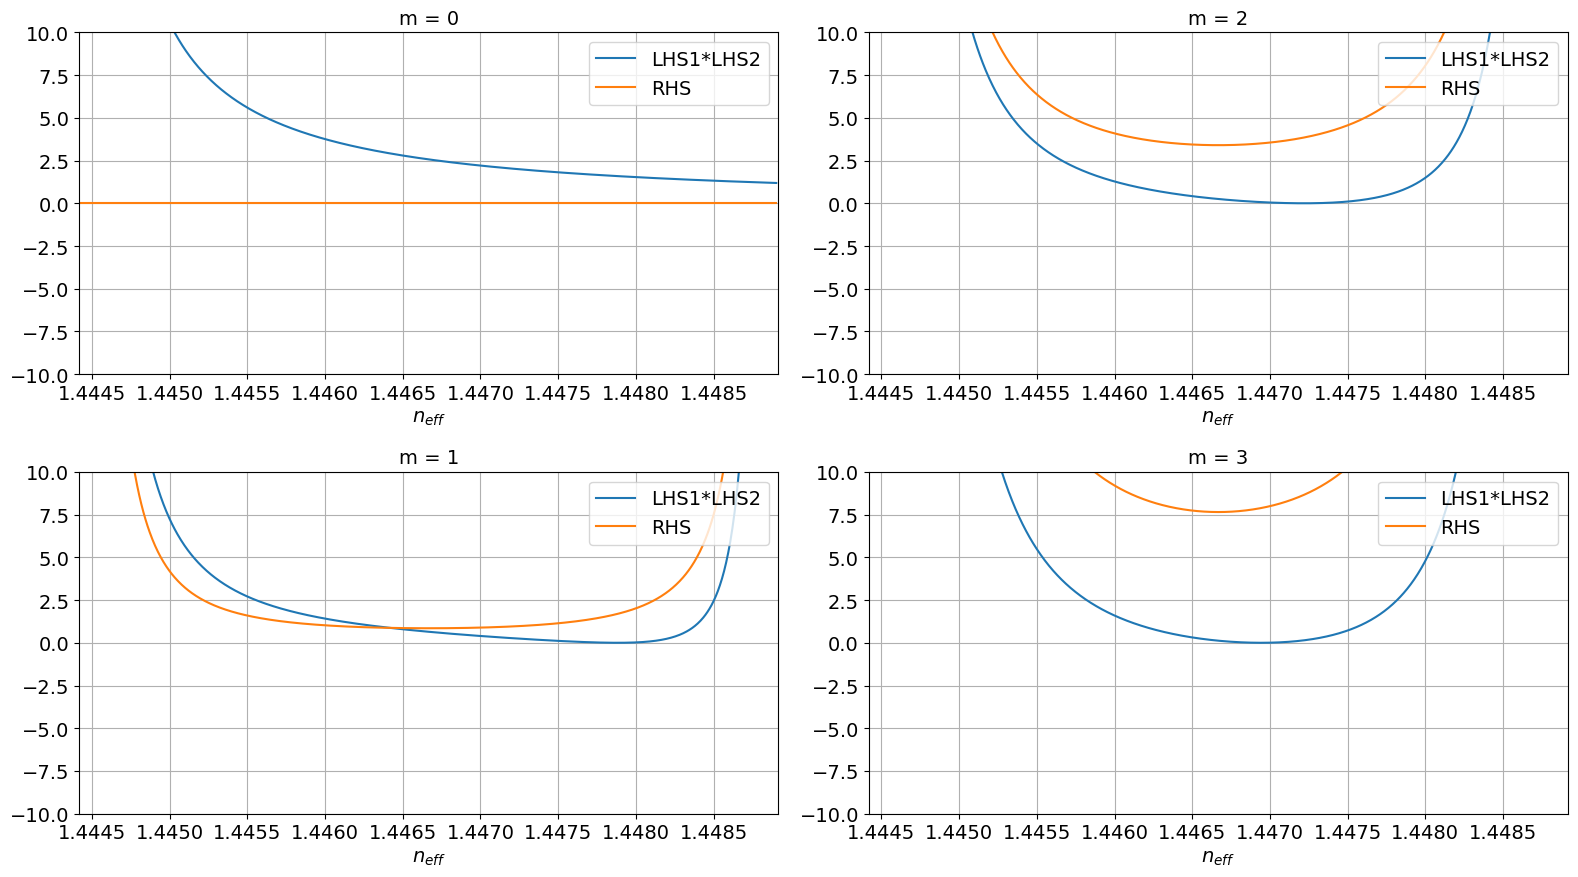

In [16]:
fc = (n2/n1)**2
fig, ax = plt.subplots(2,2,figsize=(16,9))
for m in range(4): #4 bậc m 
  # Calculation of functions : phương trình đặc tính 
  LHS1 = 1/a*(sp.jvp(m, p*a)/(p*sp.jv(m, p*a)) + sp.kvp(m, q*a)/(q*sp.kv(m,q*a)))
  LHS2 = 1/a*(sp.jvp(m, p*a)/(p*sp.jv(m, p*a)) + sp.kvp(m, q*a)/(q*sp.kv(m,q*a)*fc))
  RHS  = 1/a**2 * ((m/a)**2)*(1/(p**2)+1/(q**2))*(1/(p**2)+fc/(q**2))
  # Eliminates discontinuities
  LHS1[:-1][np.diff(LHS1) < -5] = np.nan #Xử lý điểm tiệm cận/bất tiệm cận 
  LHS2[:-1][np.diff(LHS2) < -5] = np.nan #Xử lý điểm tiệm cận/bất tiệm cận
  # Plot the functions
  ax[np.mod(m,2),int(m>1)].plot(neff, LHS1*LHS2, label = "LHS1*LHS2")
  ax[np.mod(m,2),int(m>1)].plot(neff, RHS, label = "RHS")
  ax[np.mod(m,2),int(m>1)].set_xlabel(r'$n_{eff}$', fontsize = 14)
  ax[np.mod(m,2),int(m>1)].set_title('m = %d' %(m))
  ax[np.mod(m,2),int(m>1)].set_xlim([n2, n1])
  ax[np.mod(m,2),int(m>1)].set_ylim([-10,10])
  ax[np.mod(m,2),int(m>1)].grid(True)
  ax[np.mod(m,2),int(m>1)].legend(loc='upper right')

plt.tight_layout()

### Field intensity

It is important to remember that the $z$ component of the electric field is defined as
\begin{equation}
  E_z(\rho, m, z)=A \begin{cases}
    J_m\left( p \rho \right)e^{i m \phi} e^{i \beta z}, & \rho \le a,\\
    \frac{J_m\left( pa \right)}{K_m\left( qa \right)} K_m\left( q \rho \right)e^{i m \phi} e^{i \beta z}, & \rho > a.
  \end{cases}
\end{equation}

In [17]:
#Xây dựng hàm tính toán phân bố trường Ez: 
def ez_field(x, f, z, order, pfac, qfac, radius): #x: bk, f: tần số, z: tọa độ, order: bậc m, pfac: hệ số p, qfac: hệ số q, radius: bán kính lõi a
  if x[0] < radius:
    return sp.jv(order, pfac*x) 
  else:
    return (sp.jv(order, pfac*radius)/sp.kv(order, qfac*radius))*sp.kv(order, qfac*x) 

#Kiểm tra nếu giá trị bán kính nhỏ hơn bán kính lõi, hàm trả về giá trị của hàm Bessel loại 1:(sp.jv).
#Ngược lại (khi r > a), hàm trả về giá trị trường ở lớp vỏ được nhân với hệ số biên liên tục (sp.kv).

Considering $z = 0$ and $\phi = 0$:

In [18]:
#Khởi tạo tham số và tính toán phân bố cho mode m = 1:
neff_0 = 1.4468# 1.4464 : Gán giá trị chiết suất hiệu dụng
m = 1 # Đặt bậc hàm Bessel m = 1 (tương ứng với mode HE11).
beta_0 = neff_0*k0 #tính hằng số beta
p_0 = np.sqrt((n1*k0)**2-beta_0**2) #tính tham số ngang trong lõi
q_0 = np.sqrt(beta_0**2-(n2*k0)**2) #tính tham số suy giảm vỏ
#Tạo hai mảng tọa độ bán kính p 
rho1 = np.linspace(0,a,1000) #chạy từ 0 đến bán kính lõi a
rho2 = np.linspace(a,4*a,1000) #chạy từ bán kính lõi a đến 4 lần bán kính lõi a (xem như lớp vỏ)
#Gọi hàm ez_field để tính giá trị cường độ điện trường cho vùng lõi và vùng vỏ 
Ez1_0 = ez_field(rho1, 0, 0, m, p_0, q_0, a) # sp.jv(0, p_0*rho1)
Ez2_0 = ez_field(rho2, 0, 0, m, p_0, q_0, a) # (sp.jv(0, p_0*a)/sp.kv(0, q_0*a))*sp.kv(0, q_0*rho2)

(0.0, 1.1)

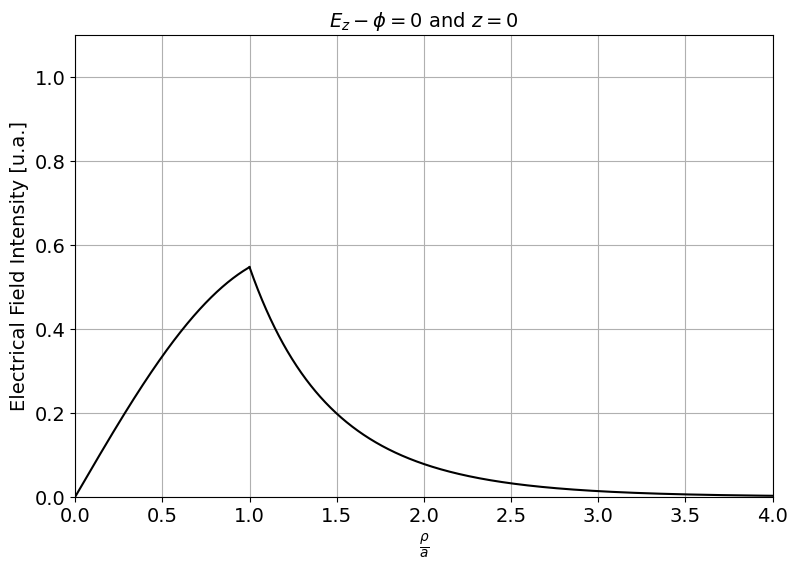

In [19]:
#Vẽ đồ thị phân bố cường độ điện trường Ez
plt.figure(figsize=(9,6))
plt.plot(rho1/a, Ez1_0, 'k')
plt.plot(rho2/a, Ez2_0, 'k')
plt.grid(True)
plt.xlabel(r'$\frac{\rho}{a}$')
plt.xlim([0,4])
plt.ylabel('Electrical Field Intensity [u.a.]')
plt.title(r'$E_z - \phi = 0$ and $z = 0$')
plt.ylim([0,1.1])

In fundamental mode, the magnitude of the $E_z$ and $H_z$ components are much smaller than the other field components for $\left(n_2/n_1\right)^2 \approx 1$. Therefore, the HE11 mode is approximately linearly polarized for weakly guiding fibers. In this case, one of the transversal components is considered null. For example, if $E_y = 0$, the $E_x$ component of the electric field of the HE11 mode is given by

\begin{equation}
  E_x(\rho, m, z) = E_0 \begin{cases}
    \frac{J_0\left( p \rho \right)}{J_0 \left( pa \right)} e^{i \beta z}, & \rho \le a,\\
    \frac{K_0\left( q \rho \right)}{K_0 \left( qa \right)} e^{i \beta z}, & \rho > a.
  \end{cases}
\end{equation}

where $E_0$ is a constant related to the mode power.

In [20]:
#Hàm tính toán điện trường ngang E_x cho Mode HE11
def ex_field_HE11_2D(x, pfac, qfac, beta, z, radius):
  if x.flatten()[0] < radius:
    return sp.jv(0, pfac*x)/sp.jv(0, pfac*radius)*np.exp(i*beta*z)
  else:
    return sp.kv(0, qfac*x)/sp.kv(0, qfac*radius)*np.exp(i*beta*z)

Text(0.5, 1.0, '$E_x - z = 0$')

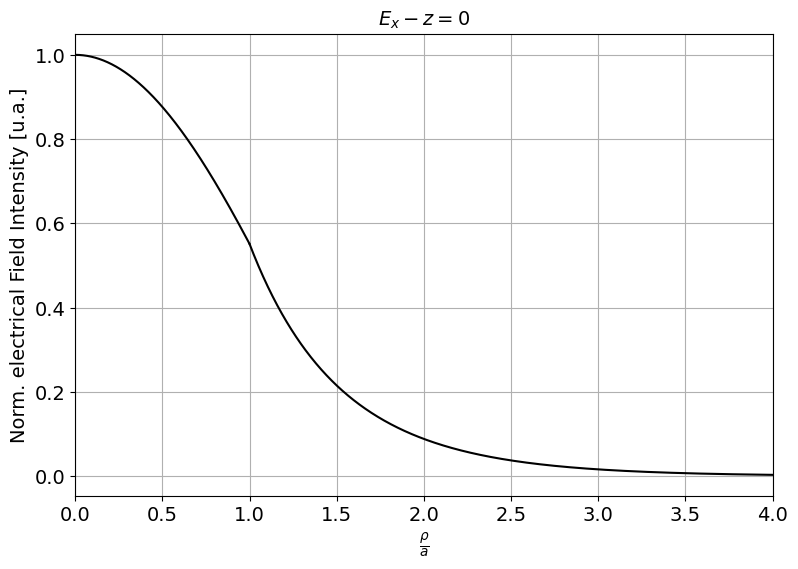

In [21]:
plt.figure(figsize=(9,6))
#Gọi hàm tính trường Ex tại mặt cắt z = 0 cho vùng lõi (Ex1_HE11_2D) và vùng vỏ (Ex2_HE11_2D).
Ex1_HE11_2D = ex_field_HE11_2D(rho1, p_0, q_0, beta_0, 0, a)
Ex2_HE11_2D = ex_field_HE11_2D(rho2, p_0, q_0, beta_0, 0, a)
# Tìm giá trị đỉnh điện trường cực đại (nằm tại tâm p = 0).
maxExField = np.max(Ex1_HE11_2D)
plt.plot(rho1/a, Ex1_HE11_2D/maxExField, 'k')
plt.plot(rho2/a, Ex2_HE11_2D/maxExField, 'k')
plt.grid(True)
plt.xlabel(r'$\frac{\rho}{a}$')
plt.xlim([0,4])
plt.ylabel('Norm. electrical Field Intensity [u.a.]')
plt.title(r'$E_x - z = 0$')

In [22]:
import matplotlib.cm as cm
#Định nghĩa hàm tính Ex dạng ma trận lưới 2D:
def ex_field_HE11(x, pfac, qfac, beta, z, radius):
  Z = np.zeros(np.shape(x))
  idxLow  = (x < radius)
  idxHigh = (x >= radius)
  Z[idxLow]  = sp.jv(0, pfac*x[idxLow])/sp.jv(0, pfac*radius)*np.exp(i*beta*z) # vùng lõi 
  Z[idxHigh] = sp.kv(0, qfac*x[idxHigh])/sp.kv(0, qfac*radius)*np.exp(i*beta*z) #vùng vỏ 
  return Z 

Text(0.5, 0.92, '$E_x$ - $HE_{11}^x$ mode')

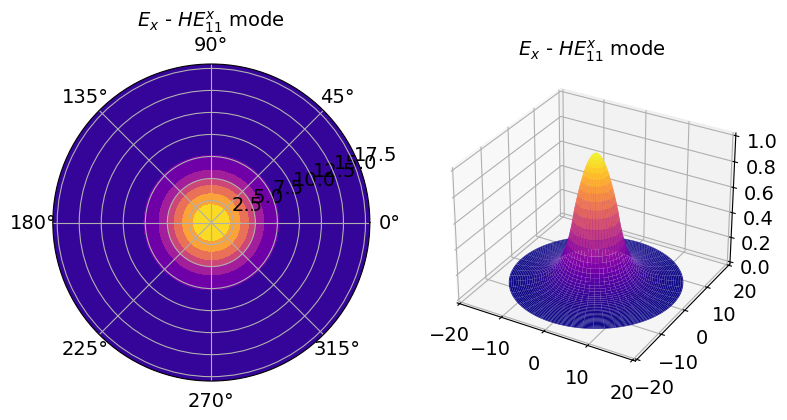

In [23]:
#Biến đổi Tọa độ Lưới & Vẽ Biểu đồ Polar (2D) + Surface (3D)
r = np.linspace(0, 4*a, 100) #100 điểm bk từ 0 đến 4a 
theta  = np.linspace(0, 2*np.pi, 100) #100 điểm góc từ 0 đến 2pi 
R, THETA = np.meshgrid(r, theta) #chuyển thành lưới 2D
X, Y = R*np.cos(THETA), R*np.sin(THETA) #biến đổi từ tọa độ cực sang tọa độ Descartes (x,y) để vẽ biểu đồ 3D
Ex_HE11_P = ex_field_HE11(R, p_0, q_0, beta_0, 0, a) #Tính toán ma trận cường độ Ex trên toàn mặt cắt ngang
maxEx_HE11_P = np.max(Ex_HE11_P) #tìm giá trị cực đại để chuẩn hóa.

fig = plt.figure(figsize=(9,6))
ax1 = fig.add_subplot(121,projection="polar")
ax1.contourf(THETA, 1e6*R, Ex_HE11_P/maxEx_HE11_P, cmap=plt.cm.plasma)
ax1.set_title('$E_x$ - $HE_{11}^x$ mode')
ax2 = fig.add_subplot(122,projection="3d")
ax2.plot_surface(1e6*X, 1e6*Y, Ex_HE11_P/maxEx_HE11_P, cmap=plt.cm.plasma)
ax2.set_title('$E_x$ - $HE_{11}^x$ mode')

The dominant component of the corresponding magnetic field is
\begin{equation}
H_y = n_2\sqrt{\frac{\varepsilon_0}{\mu_0}}E_x.
\end{equation}
This mode is biased at $x$. The same fiber supports another linearly polarized mode in the $y$ direction. Thus, single-mode fiber supports two degenerate orthogonal modes: HE$_{11}^x$ and HE$_{11}^y$.

## Spot size
It is possible to approximate the distribution of the $E_x$ component by a Gaussian distribution:
\begin{equation}
    E_x\left( \rho, z \right) = Ae^{-\left(\rho/\omega\right)^2}e^{j\beta z}
\end{equation}

where $w$ is the radius of the field, also called *spot size*. This parameter varies with the normalized frequency $V$ in the region $1.2 < V < 2.4$ according to
\begin{equation}
\frac{w}{a} \approx 0.65 + 1.619V^{-3/2} + 2.879V^{-6}
\end{equation}

In [24]:
#Hàm tính Spot Size chuẩn hóa
#: Khai báo hàm spotSize tính w dựa trên công thức Marcuse với các tham số: radius a và nrmFrq V.
def spotSize(radius, nrmFrq):
    return radius*(0.65+1.619*nrmFrq**(-1.5)+2.879*nrmFrq**(-6))
# Tính tỷ số w/a (wnorm).
wnorm = spotSize(a, V)/a
print("V = %3.2f" %(V))
print("w/a=" + str(wnorm))

V = 2.08
w/a=1.224537971819236


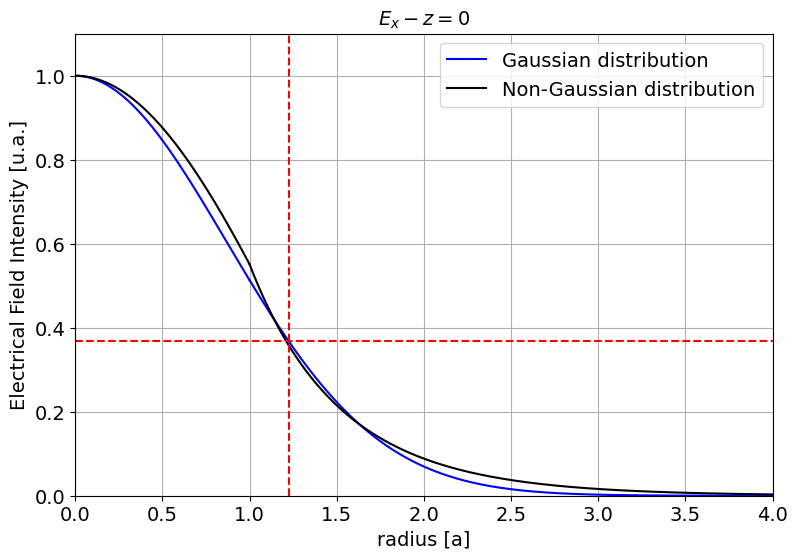

In [25]:
#So sánh Phân bố Trường Thực tế (Bessel) vs Xấp xỉ Gauss
#Khai báo hàm phân bố Gauss chuẩn hóa có biên độ cực đại bằng 1.
def ex_field_HE11_Gauss(rho, w):
    return np.exp(-(rho/w)**2)

Ex1G_HE11 = ex_field_HE11_Gauss(rho1, spotSize(a, V)) #Tính giá trị hàm Gauss cho lõi 
Ex2G_HE11 = ex_field_HE11_Gauss(rho2, spotSize(a, V)) #Tính giá trị hàm Gauss cho vỏ
#Vẽ đường cong Gauss màu xanh dương
plt.figure(figsize=(9,6))
plt.plot(rho1/a, Ex1G_HE11, 'b', label = 'Gaussian distribution')
plt.plot(rho2/a, Ex2G_HE11, 'b')

#Vẽ đường phân bố thực tế
maxEx_HE11_2D = np.max(Ex1_HE11_2D)
plt.plot(rho1/a, Ex1_HE11_2D/maxEx_HE11_2D, 'k', label = "Non-Gaussian distribution")
plt.plot(rho2/a, Ex2_HE11_2D/maxEx_HE11_2D, 'k')

#Vẽ 2 đường tiệm cận đứt nét màu đỏ
plt.plot([wnorm,wnorm], [0,1.2], 'r--')
plt.plot([0,4], [1/np.exp(1),1/np.exp(1)], 'r--')

plt.xlim(0,4)
plt.ylim(0,1.1)

plt.grid(True)
plt.xlabel('radius [a]')
plt.xlim([0,4])
plt.ylabel('Electrical Field Intensity [u.a.]')
plt.title(r'$E_x - z = 0$')
plt.legend(loc='upper right')

From the *spot size* it is possible to calculate the effective area of ​​the nucleus $A_{eff} = \pi w^2$. This is an important parameter related to nonlinear effects in optical fibers. Finally, it is possible to estimate the confinement factor from the Gaussian distribution of the $E_x$ component as:
\begin{equation}
    \Gamma = \frac{P_{core}}{P_{total}} = \frac{\int_0^a |E_x|^2 \rho d\rho}{\int_0^\infty |E_x|^2 \rho d\rho} = 1 - e^{-2\left(\frac{a}{w} \right)^2}
\end{equation}

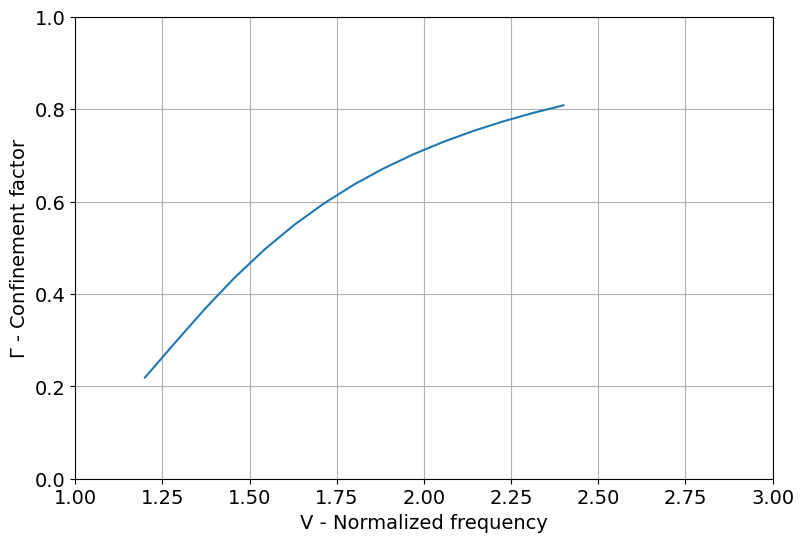

In [ ]:
V_vec = np.linspace(1.2,2.4,15) #Tạo mảng V_vec gồm 15 giá trị tần số chuẩn hóa $V$ nằm trong dải làm việc đơn mode
w_vec = spotSize(a, V_vec) # Tính bán kính vệt sáng w tương ứng cho từng giá trị $V$ bằng hàm Marcuse spotSize
gamma = 1 - np.exp(-2*(a/w_vec)**2) #Tính hệ số dẫn giữ Gamma dựa trên công thức 
plt.figure(figsize=(9,6))
plt.plot(V_vec, gamma)
plt.xlabel('V - Normalized frequency')
plt.ylabel(r'$\Gamma$ - Confinement factor')
plt.xlim(1,3)
plt.ylim(0,1)
plt.grid(True)